# A River Runs through COVID-19: 
### How the Pandemic Redistributed Angling Pressure Across Montana

# Introduction
Almost everyone experienced something out of the ordinary during the onset of the 2020 pandemic, and Montana's waterways were no exception. Montana saw approximately a 28% increase in angling pressure across the state, but where did those increases happen? That is what I will explore through this geospatial analysis. I hypothesized that this increase did not impact rivers uniformly, but concentrated to rivers that were less popular pre-pandemic. Data collected by Fish, Wildlife, and Parks from the angling surveys covers the fishing license year (March – February); I will be looking at license years 2019 and 2020 for this analysis. Data brought in from the Montana State Library was in the Coordinate Reference System (CRS) EPSG:6514, projected to NAD83(2011)/Montana State Plane; all layers were exported and reprojected to this CRS and projection system for this analysis.

FWP's angling pressure metric is calculated using the following:

$$
P_j = \sum_{i=1}^{n} \frac{E_{ij}}{R_{ij}} \cdot D_{ij} \cdot A_{ij}
$$

where:

- $P_j$ = pressure for an individual water by the $j$th residency
- $E_{ij}$ = number of eligible anglers for the $i$th wave and $j$th residency
- $D_{ij}$ = days fished on that particular water for the $i$th wave and $j$th residency
- $R_{ij}$ = number of respondents from the survey for the $i$th wave and $j$th residency
- $A_{ij}$ = adjustment factor for non-response for the $i$th wave and $j$th residency
- $n$ = number of waves in the estimate year or season
- $j$ = residency type (resident, nonresident, or total)

For this analysis, I combined the $P_j$ (resident) and $P_j$ (non-resident) metrics to examine overall fishing pressure for the state of Montana.

## Original Hypothesis:
During the onset of the COVID-19 pandemic in 2020, angling pressure from residents and non-residents became more dispersed across rivers, with angling pressure increasing on less-popular rivers compared to 2019. 

## Refined Research Question
Did 2020 angling pressure increases concentrate on rivers that were already popular in 2019, independent of their distance from population centers?

## Data Sources
1. Montana State Library:
    - [Cities](https://msl.mt.gov/geoinfo/msdi/administrative_boundaries/)
    - [Lakes](https://msl.mt.gov/geoinfo/water_information_system/nhd_high_resolution_data_download)
    - [Streams](https://msl.mt.gov/geoinfo/water_information_system/nhd_high_resolution_data_download)
    - [State Boundary](https://msl.mt.gov/geoinfo/msdi/administrative_boundaries/)
2. Fish, Wildlife & Parks 
    - [Statewide Angling Pressure Summary Reports (2019, 2020)](https://fwp.mt.gov/fish/pressure-surveys)
    - [Statewide Fisheries Management Plan Drainage Boundaries](https://fwp-gis.mt.gov/arcgis/rest/services/fish/fishViewer/MapServer/66)
    - [Fishing Access Points](https://gis-mtfwp.hub.arcgis.com/datasets/40c5d0eafa9343249239b71cbd4e95b6_0/explore?location=46.831007%2C-109.511871%2C6)


In [1]:
# Import libraries for this notebook
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import numpy as np
from PIL import Image
import os
# Keep errors from displaying
os.environ["PROJ_LIB"] = "/opt/conda/envs/gds/share/proj"

# Read in geopackage
df = gpd.read_file("../Data/project1_pythondata.gpkg")

## Statewide View
![](../Figures/2020_access_pctchange.png)

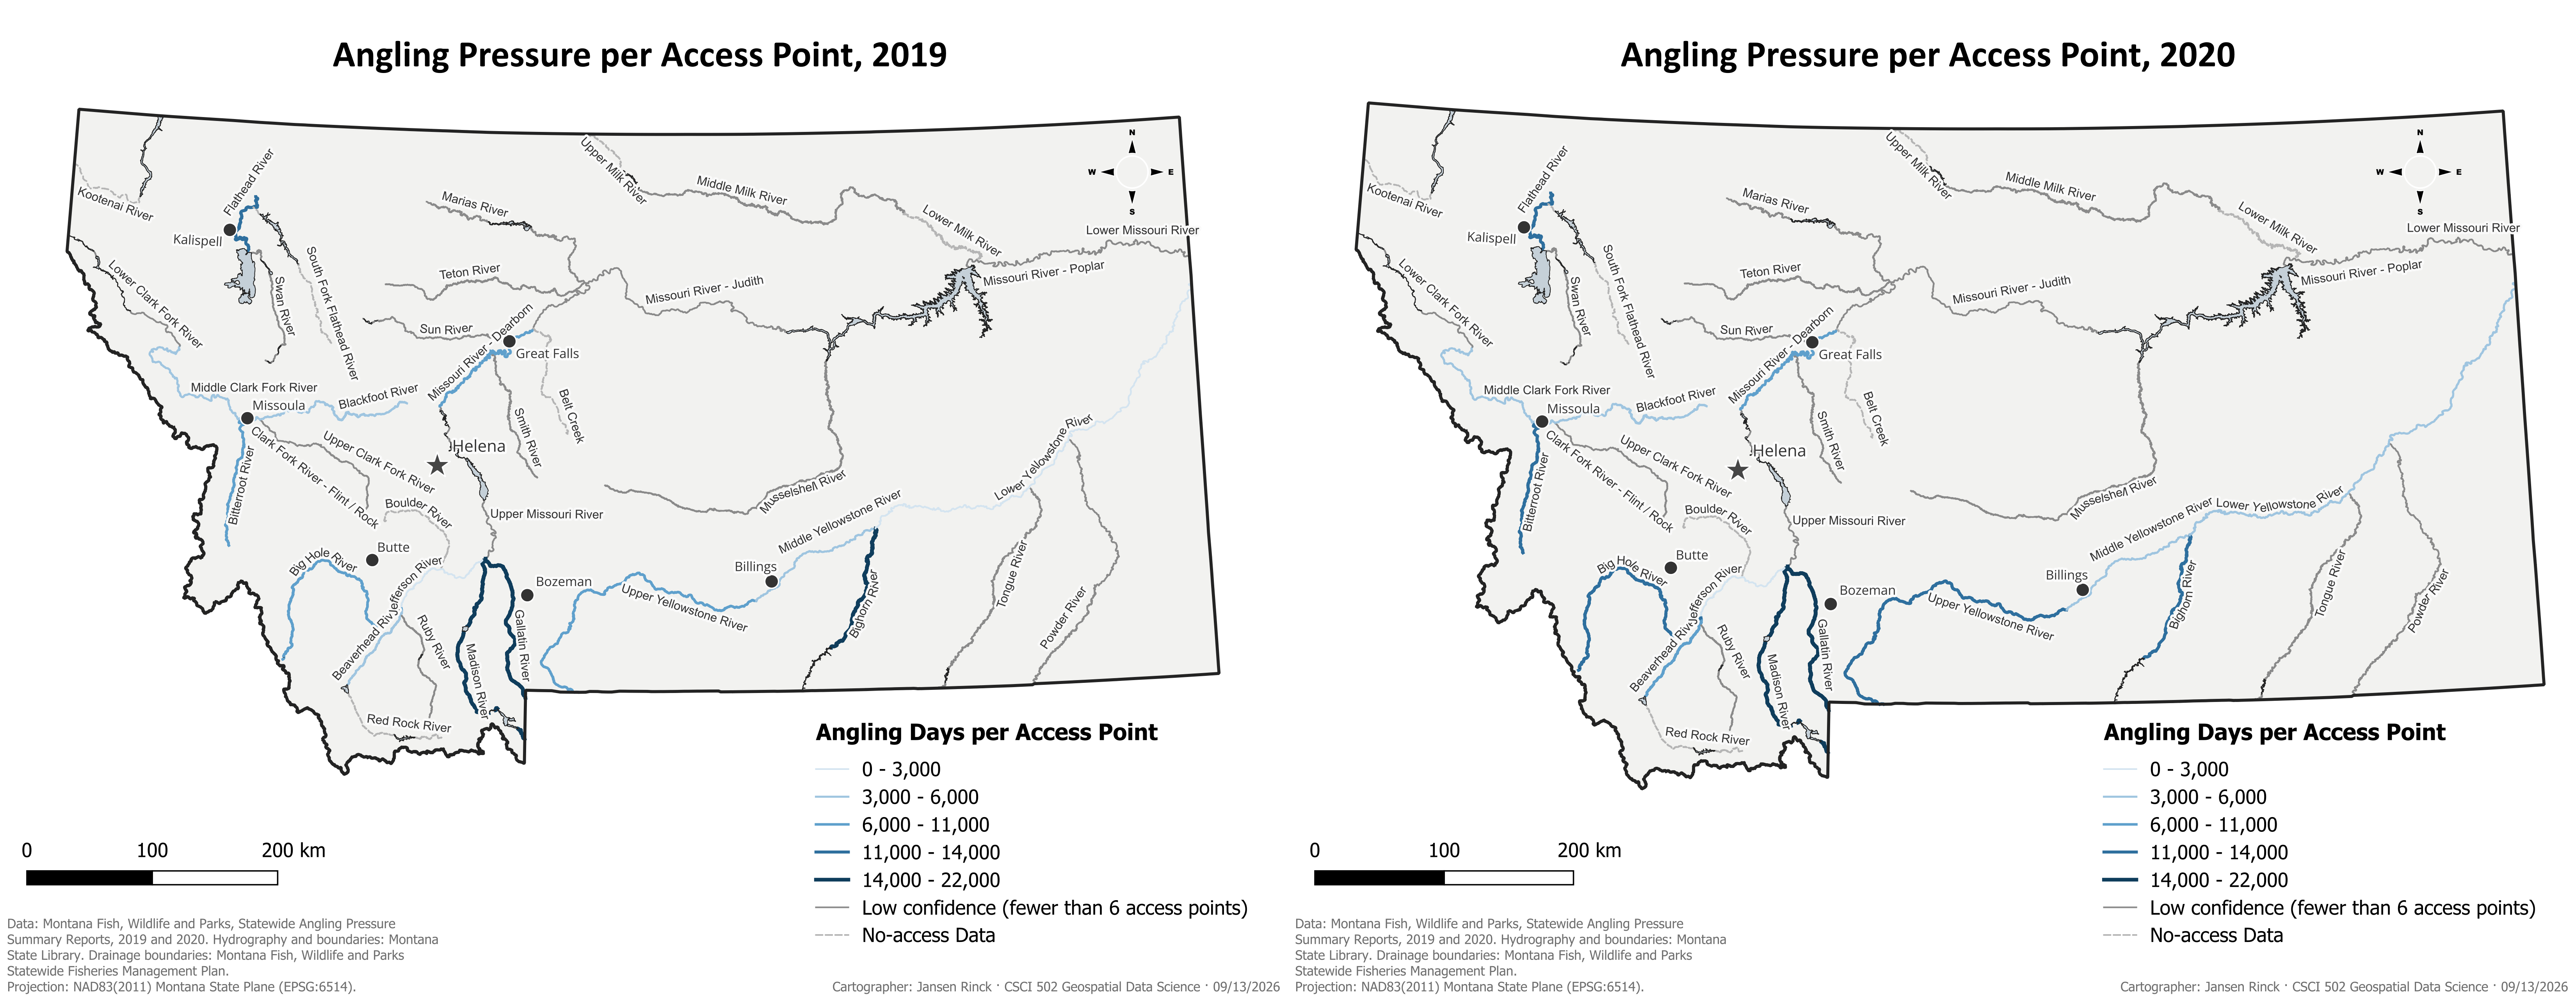

In [2]:
# Open the two QGIS map exports so we can combine them into one image
img1 = Image.open("../Figures/2019_access.png")
img2 = Image.open("../Figures/2020_access.png")

# Figure out how big the combined canvas needs to be: wide enough for both images side by side, tall enough for the taller one
total_width = img1.width + img2.width
max_height = max(img1.height, img2.height)

# Create a blank white canvas of that size to paste both images onto
combined = Image.new("RGB", (total_width, max_height), "white")
# Paste the 2019 map at the left edge of the canvas
combined.paste(img1, (0, 0))
# Paste the 2020 map directly to the right of the first one
combined.paste(img2, (img1.width, 0))
combined

View 1 (Top). Side-by-side statewide map view of the angling pressure per FWP fishing access point (days/access point) for 2019 and 2020 for Montana rivers. In both maps, line color and thickness scale together with pressure: pale, thin lines indicate low pressure, and dark, thick lines indicate high pressure.

View 1 (Bottom). Statewide map view of the change in angling pressure per FWP fishing access point (days/access point) from 2019 to 2020 for Montana rivers. Line color indicates the direction of change - blue for a decrease, and red for an increase. The thickness of the lines indicates the magnitude of the change (independent of the direction of change) - thick lines indicating the largest change, and thin lines representing little or no change. Rivers with six or fewer access points are shown in gray, and rivers with no access data are displayed with a dashed line.

### Discussion 
This first view examines how angling pressure changed per fishing access point between 2019 and 2020, normalizing by access count rather than river length.

The Upper Missouri fell below the threshold of six access points I set for this analysis (more on that below in the data processing section); however, it still showed a very large increase in angling pressure (+125%). It is clear that this stretch of water, while relatively short, is very popular. Due to its short length and low access count, this ratio is more sensitive to single trips than longer rivers with more access points - one additional trip has a larger impact on the average when the denominator is small.

Looking at the map above, it is apparent that this normalization highlights geospatial trends that a simpler metric might obscure. The Jefferson River increased by 83% under this access-point metric - a notably large jump. The Jefferson River and the Beaverhead River both showed the largest increases in angling pressure per access point. Is this a trend that indicates some truth behind my hypothesis?

### Data Processing

To normalize Montana streams by FWP fishing access points, I first had to filter the raw access site data down to points actually located along the rivers examined in this analysis, since the dataset also includes points on lakes and reservoirs. Matching each point to its corresponding river turned out to be difficult - the access point data didn't have a field that specified what river or waterbody each point lies on, so I resolved this by classifying each point by proximity, comparing its distance to the nearest river. Once that data was classified and parsed, I used the "Statistics by Category" tool to group the points by individual river and get counts for each. With the access point count joined back onto the stream data I appended the count as a new attribute based on the shared river name field - I use this same join method throughout this analysis. I calculated angling days per access point for each river in 2019 and 2020, then found the percent change between the two years. Looking at the resulting percentages, it was clear there was a steep drop-off in pressure metrics for rivers that had fewer than six access points, so I excluded rivers below that threshold for this part of the analysis.

![](../Figures/Angling_Pressure_Overview.png)

View 2: Statewide map view of the change in angling pressure per stream mile (days/mi) from 2019 to 2020 for Montana rivers. Line color indicates the direction of change - blue for a decrease and red for an increase. The thickness of the lines represents the magnitude of the change - thick lines are for the largest increases/decreases while the thinnest lines represent little or no change.


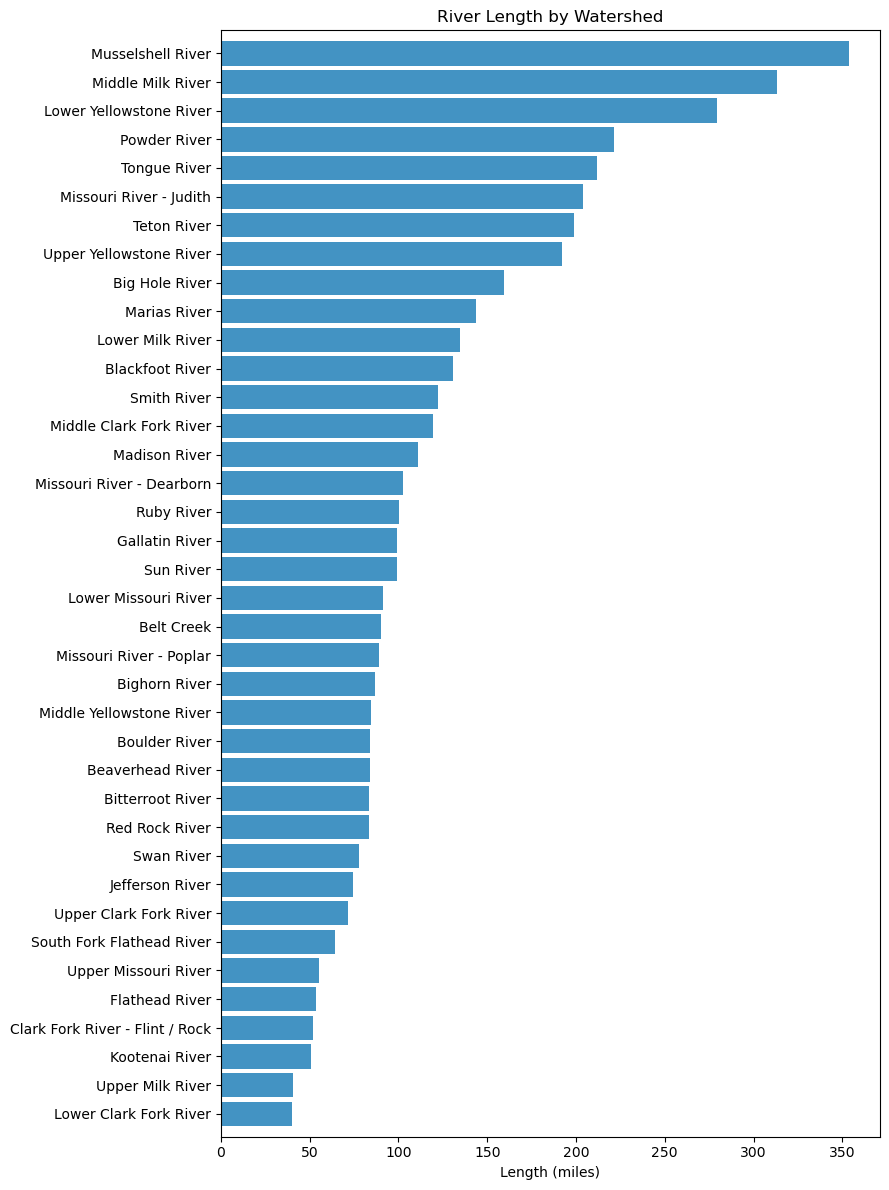

In [3]:
# Get river length's that are not null
plot_river = df[df["seg_miles"].notna()].copy()
# Sort lengths ascending
plot_river = plot_river.sort_values("seg_miles", ascending=True)

#Create a bar chart - plot river and length
fig, ax = plt.subplots(figsize=(9, 12))
ax.barh(plot_river["DRAINNAME"], plot_river["seg_miles"], color="#4393C3", height=0.85)
ax.set_xlabel("Length (miles)")
ax.set_title("River Length by Watershed")
ax.margins(y=0.01)

plt.tight_layout()
plt.show()

Figure 1. Trimmed river length (miles) by Montana drainage.

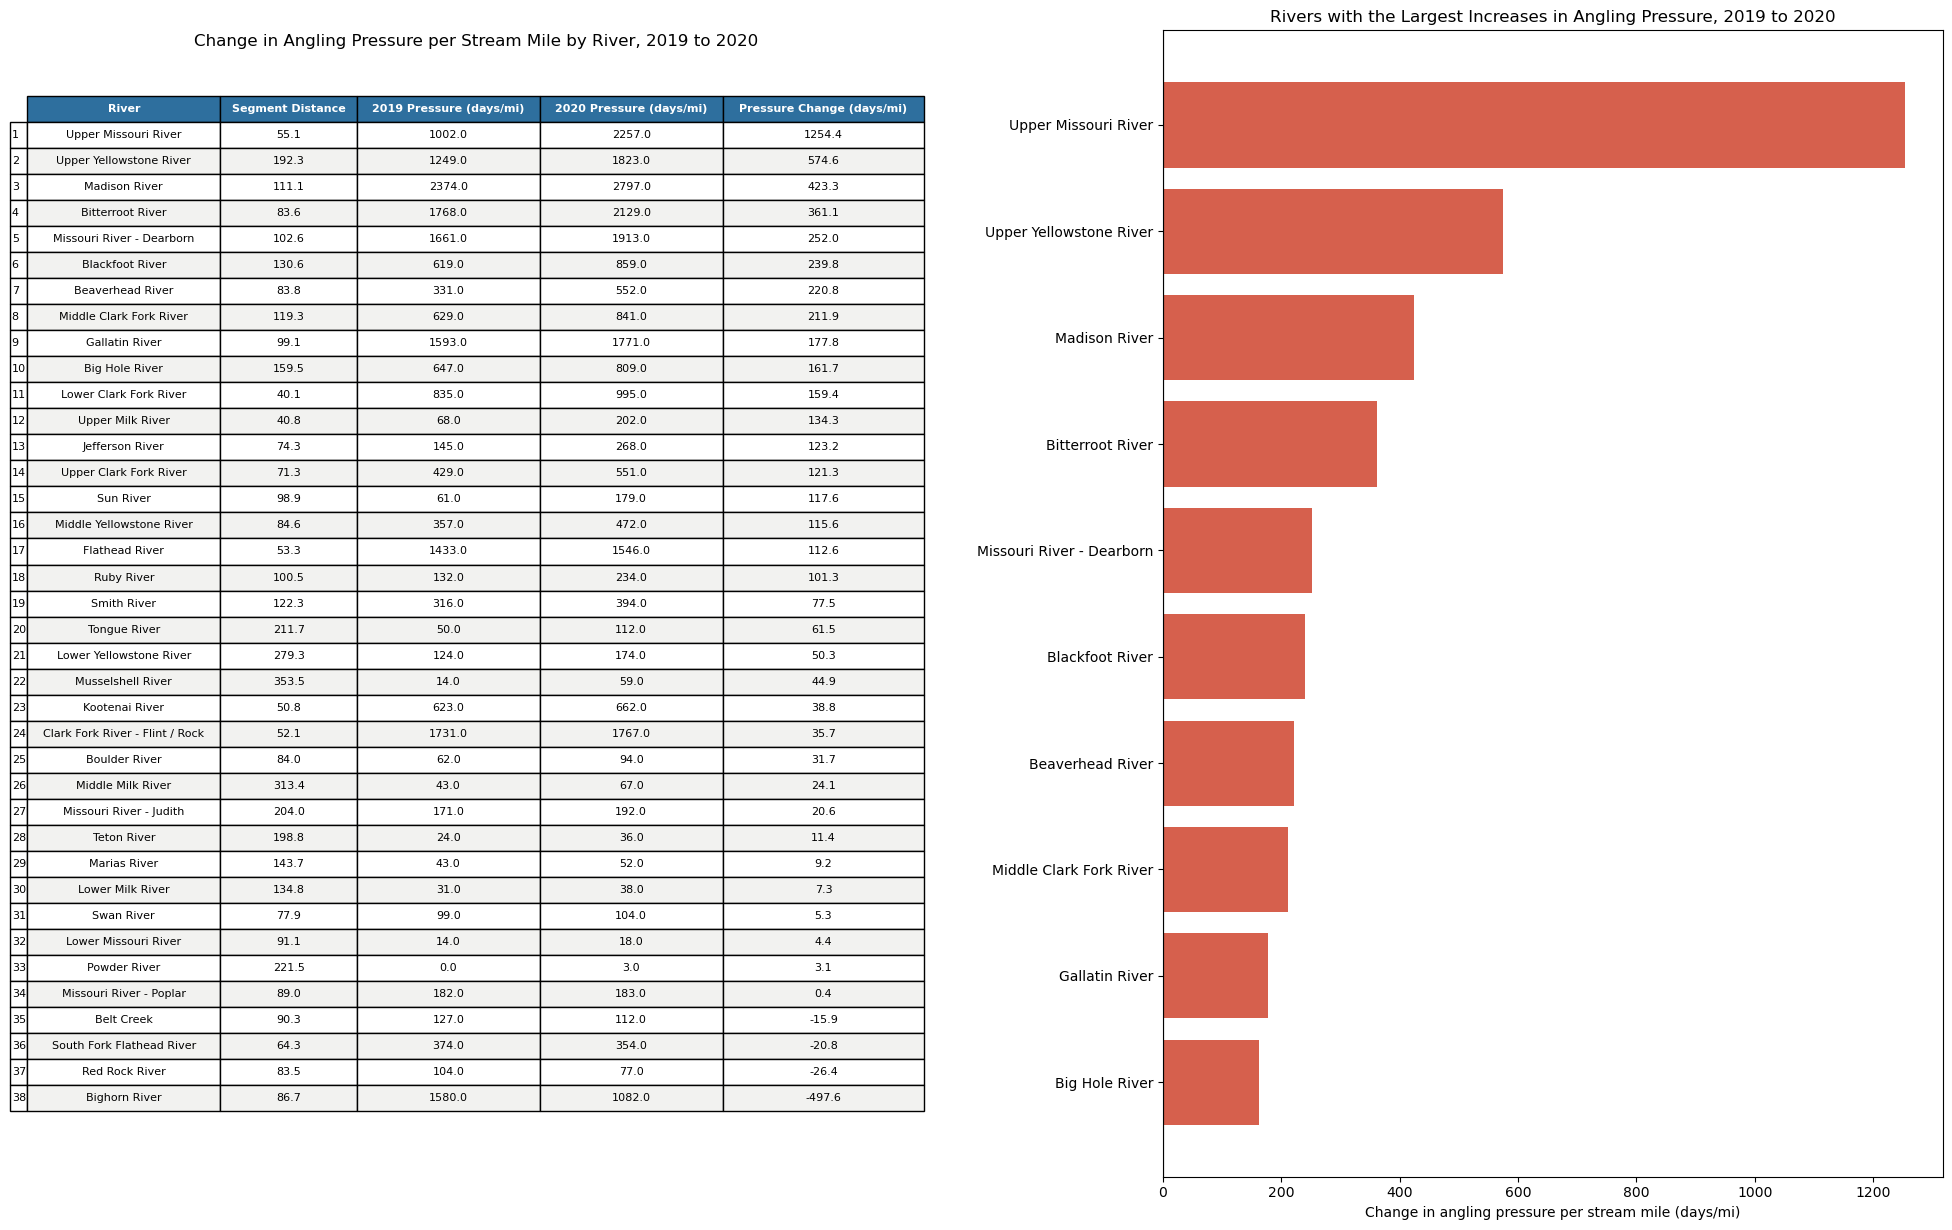

In [4]:
# Calculate the 75th percentile of a column and return the top 25%
def split_by_quartile(data, column):
    q3 = data[column].quantile(0.75)
    upper_quartile = data[data[column] >= q3].copy()
    return upper_quartile
    
# Build the bar chart data
plot_data = df[df["chg_per_mi"].notna()].copy()
plot_data = plot_data.sort_values("chg_per_mi", ascending=True)
upper_quartile = split_by_quartile(plot_data, "chg_per_mi")

# Build table data
table_data_permile = df.copy()
table_data_permile = table_data_permile.sort_values("chg_per_mi", ascending=False)

# Name the table columns
table_data_permile = table_data_permile[[
    "DRAINNAME", "seg_miles", "press_mi_19", 
    "press_mi_20", "chg_per_mi"
]].rename(columns={
    "DRAINNAME": "River",
    "seg_miles": "Segment Distance",
    "press_mi_19": "2019 Pressure (days/mi)",
    "press_mi_20": "2020 Pressure (days/mi)",
    "chg_per_mi": "Pressure Change (days/mi)"
})

# Round table values
table_data_permile["Segment Distance"] = table_data_permile["Segment Distance"].round(1)
table_data_permile["2019 Pressure (days/mi)"] = table_data_permile["2019 Pressure (days/mi)"].round(0)
table_data_permile["2020 Pressure (days/mi)"] = table_data_permile["2020 Pressure (days/mi)"].round(0)
table_data_permile["Pressure Change (days/mi)"] = table_data_permile["Pressure Change (days/mi)"].round(1)

# Reset table index
table_data_permile = table_data_permile.reset_index(drop=True)
table_data_permile.index = table_data_permile.index + 1

# THIS IS NOT MY CODE
# --- Combined figure: table on the left, bar chart on the right ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, len(table_data_permile) * 0.3 + 1))

# Left: styled table
ax1.axis("off")
tbl = ax1.table(
    cellText=table_data_permile.values,
    colLabels=table_data_permile.columns,
    rowLabels=table_data_permile.index,
    cellLoc="center",
    loc="center"
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(8)
tbl.scale(1, 1.3)
tbl.auto_set_column_width(col=list(range(len(table_data_permile.columns))))

for col in range(len(table_data_permile.columns)):
    tbl[0, col].set_facecolor("#2E6F9E")
    tbl[0, col].set_text_props(color="white", weight="bold")

for row in range(1, len(table_data_permile) + 1):
    color = "#F2F2F0" if row % 2 == 0 else "white"
    for col in range(len(table_data_permile.columns)):
        tbl[row, col].set_facecolor(color)
# ABOVE IS NOT MY CODE

ax1.set_title("Change in Angling Pressure per Stream Mile by River, 2019 to 2020", pad=-100000000000000000)

# Right: bar chart - plot river name and angling increase per mile
colors = ["#4393C3" if v < 0 else "#D6604D" for v in upper_quartile["chg_per_mi"]]
ax2.barh(upper_quartile["DRAINNAME"], upper_quartile["chg_per_mi"], color=colors)
ax2.set_xlabel("Change in angling pressure per stream mile (days/mi)")
ax2.set_title("Rivers with the Largest Increases in Angling Pressure, 2019 to 2020")
ax2.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

Table 1. River segment length (miles), alongside relative angling pressure (days/mi) in 2019 to 2020, and the change in pressure between years. 

Figure 2. Change in angling pressure per stream mile (days/mi) in 2019 and 2020 for the 10 rivers with the largest increase.

## Discussion - Second Iteration
When looking more closely at the data, you can see from the map and the table/chart above that rivers with less pressure per mile tend to be longer - which raises the question of whether this reflects a true pattern or is simply a characteristic of river length itself. For example, after lakes and reservoirs were trimmed from the Upper Missouri, it lost 51% of its length, shrinking the denominator of the per-mile calculation and inflating the resulting metric. The Upper Missouri showed the greatest increase of any river in this study, despite being one of the shortest. This effect is clear when looking at the gap between the Upper Missouri and the second-ranked Upper Yellowstone, which more than doubles (1254.4 vs. 574.6), while the remaining rivers show a relatively smooth decline in pressure. 

Looking closely at the table, some of the longest rivers show very little increase in angling pressure. I suspect this is because many of these longer rivers run through the eastern part of the state, where fisheries provide fewer angling opportunities and are generally less desirable - some carry little to no trout and contain mostly warm-water species. Typically, when we think of high-pressure rivers in Montana, we picture trout streams; however, I will explore different normalization methods below to see how the geospatial patterns might change.


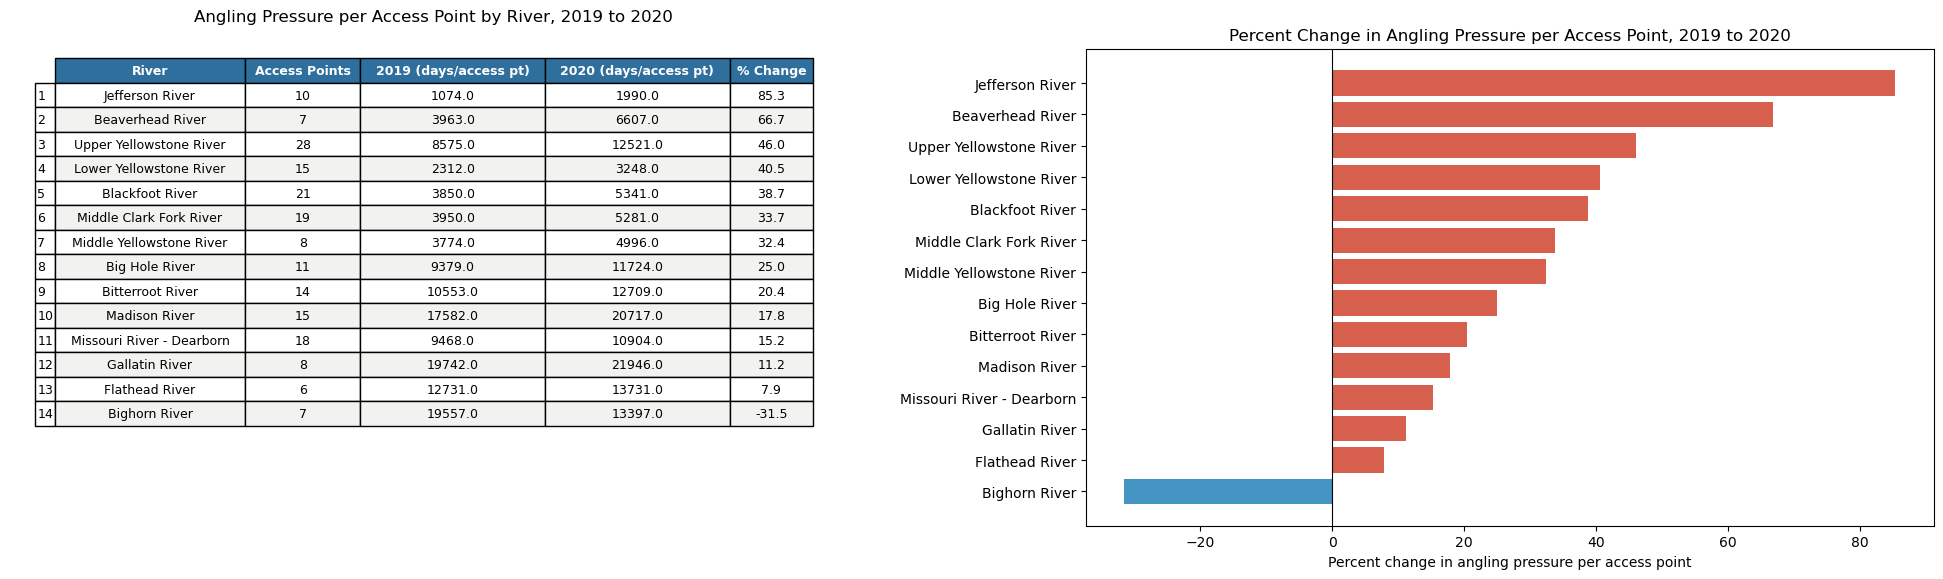

In [5]:
# Extract all features that have more than 6 access points ("reliable")
table_data_access = df[df["data_confidence"] == "reliable"].copy()
# Sort features that are "reliable" by percent change per access point in descending order
table_data_access = table_data_access.sort_values("pct_change_access", ascending=False)

# Specify columns in table and rename 
table_data_access = table_data_access[[
    "DRAINNAME", "count", "press_per_access_19", 
    "press_per_access_20", "pct_change_access"
]].rename(columns={
    "DRAINNAME": "River",
    "count": "Access Points",
    "press_per_access_19": "2019 (days/access pt)",
    "press_per_access_20": "2020 (days/access pt)",
    "pct_change_access": "% Change"
})

# Round table data
table_data_access["2019 (days/access pt)"] = table_data_access["2019 (days/access pt)"].round(0)
table_data_access["2020 (days/access pt)"] = table_data_access["2020 (days/access pt)"].round(0)
table_data_access["% Change"] = table_data_access["% Change"].round(1)

# Reset table index
table_data_access = table_data_access.reset_index(drop=True)
table_data_access.index = table_data_access.index + 1

plot_table = table_data_access.sort_values("% Change", ascending=True)

# THIS IS NOT MY CODE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, len(table_data_access) * 0.35 + 1))

# Left: styled table
ax1.axis("off")
tbl = ax1.table(
    cellText=table_data_access.values,
    colLabels=table_data_access.columns,
    rowLabels=table_data_access.index,
    cellLoc="center",
    loc="upper center"
)
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1, 1.4)
tbl.auto_set_column_width(col=list(range(len(table_data_access.columns))))

for col in range(len(table_data_access.columns)):
    tbl[0, col].set_facecolor("#2E6F9E")
    tbl[0, col].set_text_props(color="white", weight="bold")

for row in range(1, len(table_data_access) + 1):
    color = "#F2F2F0" if row % 2 == 0 else "white"
    for col in range(len(table_data_access.columns)):
        tbl[row, col].set_facecolor(color)
# ABOVE IS NOT MY CODE

ax1.set_title("Angling Pressure per Access Point by River, 2019 to 2020", pad=20)

# Right: bar chart - plot river name and increase pressure per access point
colors = ["#4393C3" if v < 0 else "#D6604D" for v in plot_table["% Change"]]
ax2.barh(plot_table["River"], plot_table["% Change"], color=colors)
ax2.set_xlabel("Percent change in angling pressure per access point")
ax2.set_title("Percent Change in Angling Pressure per Access Point, 2019 to 2020")
ax2.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

Table 2 (Left). Angling pressure (days/access point) for the 14 Montana Rivers with 6 or more FWP access points, sorted by percent change in descending order.

Figure 3 (Right). Relationship between the percent change in angling pressure for each of the 14 Montana rivers with 6 or more FWP fishing access points.

## Discussion - Third Iteration

This view adds a ranked, numeric list that allows for direct comparisons of the magnitude of percent change in angling pressure - comparisons that aren't possible from the map alone. The Beaverhead and Jefferson rank at the top and share similar characteristics: both lie in southwestern Montana and have moderate access counts relative to the rest of the list. The Bighorn is the clearest outlier in this data, and is the only river that showed a decrease in angling pressure. I have a few ideas about why, which I'll discuss later. Whether these rankings relate to how popular each river already was in 2019 is worth checking - see that comparison below.


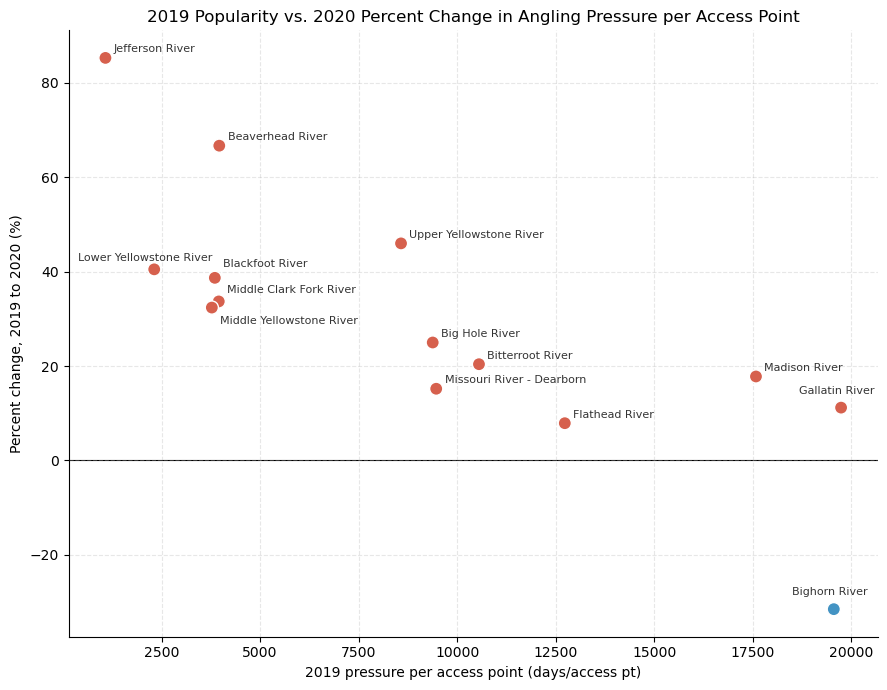

In [6]:
# Create copy of plot data
plot_data = table_data_access.copy()

# define x and y axis data
x = plot_data["2019 (days/access pt)"]
y = plot_data["% Change"]

fig, ax = plt.subplots(figsize=(9, 7))

# Color points by direction of change, matching your above maps
colors = ["#4393C3" if v < 0 else "#D6604D" for v in y]
ax.scatter(x, y, color=colors, s=90, zorder=3, edgecolor="white", linewidth=1)

custom_offsets = {
    "Middle Clark Fork River": (6, 6),
    "Middle Yellowstone River": (6, -12),
    "Blackfoot River": (6, 8),
    "Lower Yellowstone River": (-55, 6),
    "Gallatin River": (-30, 10),
    "Bighorn River": (-30, 10)
}
default_offset = (6, 4)

# Label points 
for i, row in plot_data.iterrows():
    offset = custom_offsets.get(row["River"], default_offset)
    ax.annotate(
        row["River"],
        (row["2019 (days/access pt)"], row["% Change"]),
        textcoords="offset points",
        xytext=offset,
        fontsize=8,
        color="#333333"
    )
    
# Label and style the scatterplot 
ax.axhline(0, color="black", linewidth=0.8, zorder=1)
ax.set_xlabel("2019 pressure per access point (days/access pt)")
ax.set_ylabel("Percent change, 2019 to 2020 (%)")
ax.set_title("2019 Popularity vs. 2020 Percent Change in Angling Pressure per Access Point")

# Style plot (help from claude)
ax.grid(True, linestyle="--", alpha=0.3, zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Figure 4. Relationship between 2019 baseline angling pressure per access point and percent change in pressure from 2019 to 2020, for the fourteen rivers with six or more FWP access points. Each point represents one river; color indicates direction of change, matching the convention used throughout this analysis.


### Discussion - Fourth Iteration

There is a strong negative correlation between 2019 pressure per access point and the percent change from 2019 to 2020. The scatterplot above shows that in general, rivers with lower 2019 pressure showed large percentage increases in 2020. While this doesn't prove that more remote rivers showed a large increase in angling pressure, it does provide evidence that less popular rivers showed a large increase in angling pressure. Setting the Bighorn River aside, the Gallatin and Madison rivers were the most popular in 2019 and showed a relatively modest increase in fishing pressure - further evidence that anglers sought out less popular waters in 2020. The limitation of this study is sample size - fourteen rivers is a small dataset, and a strong correlation drawn from so few points should be viewed cautiously.


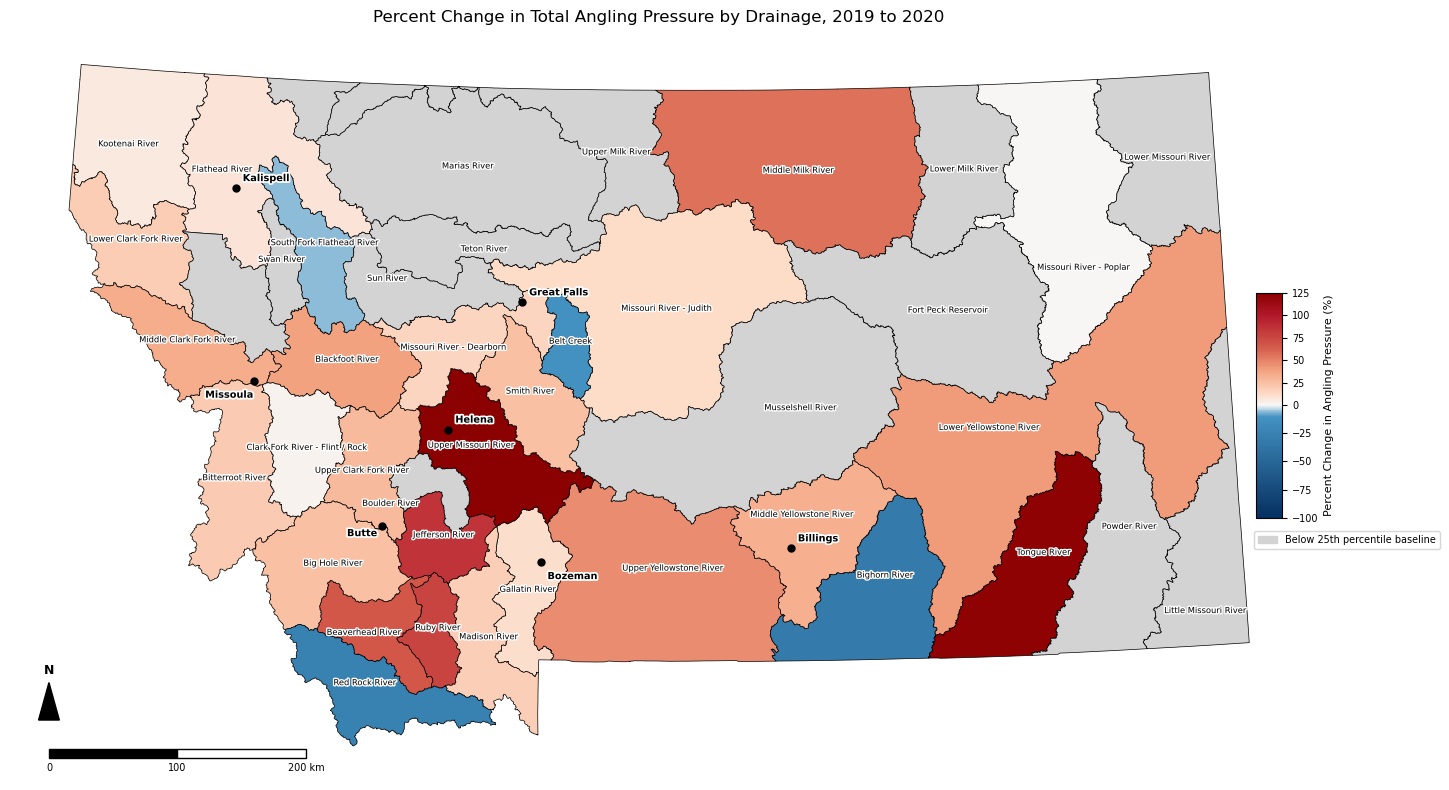

In [7]:
# I USED CLAUDE TO HELP WITH SEGMENTS OF THIS CODE BUT HAVE TAKEN THE TIME TO COMMENT OUT AND UNDERSTAND

import warnings
warnings.filterwarnings("ignore", message="This figure includes Axes that are not compatible with tight_layout")

# Read in drainage and city geospatial data
drainages = gpd.read_file("../Data/fwp_drainages_6514_geomfix.gpkg")
cities = gpd.read_file("../Data/montana_cities_POINT.gpkg")

# Create a copy of the river and pressure data
pressure_by_drainage = df[["DRAINNAME", "stream_pressure_2019", "stream_pressure_2020"]].copy()

# Calculate the 25th percentile for baseline threshold
MIN_BASELINE = pressure_by_drainage["stream_pressure_2019"].quantile(0.25)

# Calculate the % change in angling pressure from 2019 to 2020 that were above the 25th percentile
pressure_by_drainage["pct_change_pressure"] = np.nan
reliable_mask = pressure_by_drainage["stream_pressure_2019"] >= MIN_BASELINE
pressure_by_drainage.loc[reliable_mask, "pct_change_pressure"] = (
    (pressure_by_drainage.loc[reliable_mask, "stream_pressure_2020"] 
     - pressure_by_drainage.loc[reliable_mask, "stream_pressure_2019"])
    / pressure_by_drainage.loc[reliable_mask, "stream_pressure_2019"] * 100
)

# Join pressure_by_drainage to river/drainage name for cloropleth map
choropleth_data = drainages.merge(pressure_by_drainage, on="DRAINNAME", how="left")

# Rearrange drainage labels to resolve labeling conflics
drainage_offsets = {
    "Middle Yellowstone River": (2, 20),
    "Boulder River": (-15, -8),
    "Ruby River": (7, 0),
    "Madison River": (12, -6),
    "Little Missouri River": (-9, -90),
    "Missouri River - Poplar": (30, -35)
}

# Skip these labels 
default_drainage_offset = (0, 0)
skip_labels = {"NA", "NA - St. Mary and Belly Rivers", "NA - Milk River Headwaters"}

fig, ax = plt.subplots(figsize=(18, 8))

# Configure graduated scale bar for %change in angling pressure
palette_colors = ["#053061", "#4393C3", "#F7F7F7", "#FDDBC7", "#F4A582", "#D6604D", "#B2182B", "#8B0000"]
stops = [0.0, 0.45, 0.5, 0.55, 0.65, 0.75, 0.9, 1.0]
cmap = mcolors.LinearSegmentedColormap.from_list(
    "custom_pctchange",
    list(zip(stops, palette_colors))
)
norm = mcolors.TwoSlopeNorm(vmin=-100, vcenter=0, vmax=125)

# Plot map (help styling from claude)
choropleth_data.plot(
    column="pct_change_pressure",
    cmap=cmap,
    norm=norm,
    linewidth=0.5,
    edgecolor="black",
    legend=False,
    ax=ax,
    missing_kwds={"color": "lightgrey", "label": "Below 25th percentile baseline"}
)

# Label data (help from claude) BELOW
for idx, row in choropleth_data.iterrows():
    if row["geometry"].area > 5e8 and row["DRAINNAME"] not in skip_labels:
        centroid = row["geometry"].representative_point()
        offset = drainage_offsets.get(row["DRAINNAME"], default_drainage_offset)
        ax.annotate(
            text=row["DRAINNAME"],
            xy=(centroid.x, centroid.y),
            xytext=offset,
            textcoords="offset points",
            ha="center",
            fontsize=6,
            color="black",
            path_effects=[pe.withStroke(linewidth=2, foreground="white")]
        )

city_offsets = {
    "Kalispell": (5, 5), "Missoula": (-35, -12), "Great Falls": (5, 5),
    "Helena": (5, 5), "Bozeman": (5, -12), "Billings": (5, 5), "Butte": (-25, -7)
}
default_city_offset = (5, 5)

cities.plot(ax=ax, color="black", markersize=25, zorder=5)
for idx, row in cities.iterrows():
    pt = row["geometry"].centroid
    offset = city_offsets.get(row["NAME"], default_city_offset)
    ax.annotate(
        text=row["NAME"],
        xy=(pt.x, pt.y),
        xytext=offset,
        textcoords="offset points",
        fontsize=7,
        weight="bold",
        color="black",
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")]
    )
# Label data (help from claude) ABOVE

# Style and place graduated color ramp (help from claude) BELOW
cax = inset_axes(ax, width="2%", height="30%", loc="center right",
                  bbox_to_anchor=(-0.02, 0, 1, 1), bbox_transform=ax.transAxes, borderpad=0)
sm = cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Percent Change in Angling Pressure (%)", fontsize=8)
cbar.ax.tick_params(labelsize=7)
# Style and place graduated color ramp (help from claude) ABOVE

# Add patch for drainages below 25th percentile
nodata_patch = mpatches.Patch(color="lightgrey", label="Below 25th percentile baseline")
ax.legend(handles=[nodata_patch], loc="center right",
          bbox_to_anchor=(0.105, 0, 1, 0.64), bbox_transform=ax.transAxes,
          fontsize=7, frameon=True)

# Scale bar for map (help from claude) BELOW
xlim = ax.get_xlim()
ylim = ax.get_ylim()
bar_x0 = xlim[0] + (xlim[1] - xlim[0]) * 0.03
bar_y0 = ylim[0] + (ylim[1] - ylim[0]) * 0.03
segment_m = 100_000
bar_height = (ylim[1] - ylim[0]) * 0.012

ax.add_patch(mpatches.Rectangle((bar_x0, bar_y0), segment_m, bar_height,
                                 facecolor="black", edgecolor="black", zorder=6))
ax.add_patch(mpatches.Rectangle((bar_x0 + segment_m, bar_y0), segment_m, bar_height,
                                 facecolor="white", edgecolor="black", zorder=6))
for i, label in enumerate(["0", "100", "200 km"]):
    ax.text(bar_x0 + i * segment_m, bar_y0 - bar_height * 1.5, label,
            ha="center", fontsize=7, zorder=6)
# Scale bar for map (help from claude) ABOVE

# North arrow for map (help from claude) BELOW
compass_cx = bar_x0
compass_base_y = bar_y0 + (ylim[1] - ylim[0]) * 0.05
compass_half_w = (xlim[1] - xlim[0]) * 0.008
compass_h = (ylim[1] - ylim[0]) * 0.05

ax.add_patch(mpatches.Polygon(
    [(compass_cx, compass_base_y + compass_h),
     (compass_cx - compass_half_w, compass_base_y),
     (compass_cx + compass_half_w, compass_base_y)],
    closed=True, facecolor="black", edgecolor="black", zorder=6
))

ax.text(compass_cx, compass_base_y + compass_h * 1.15, "N",
        ha="center", va="bottom", fontsize=9, weight="bold", zorder=6)
# North arrow for map (help from claude) ABOVE

# Set title for map
ax.set_title("Percent Change in Total Angling Pressure by Drainage, 2019 to 2020")
ax.set_axis_off()

plt.tight_layout()
plt.show()

View 3. Statewide choropleth view of Montana showing percent change in angling pressure by FWP fisheries management drainage boundary, calculated directly from total angler-days rather than normalized by river length or access point count.

## Discussion - Final Iteration

For the last iteration of this analysis, I am looking at raw total stream pressure per drainage, with no normalizing metric applied. The Tongue River drainage is the standout result in this view of the dataset. This view highlights something the other normalization metrics missed entirely. Despite being one of the longest rivers (211.7 miles) with only one access point, the Tongue River showed a 122.6% increase — from 10,626 days in 2019 to 23,653 days in 2020. This points to real limitations in the previous iterations of this analysis. Also noteworthy: the Upper Missouri River drainage shows a large increase here too, one that can no longer be attributed to ratio sensitivity. Perhaps aggregating raw total pressure at the drainage level, instead of dividing by either length or access count, is the most telling display of this data.

The other outlier worth addressing is the Bighorn River drainage, which experienced a large decrease in angling pressure despite being a renowned fishery. The Bighorn flows through the heart of the Crow Indian Reservation, which enacted strict COVID-19 measures and discouraged non-tribal member recreational travel. In late March 2020, the Crow Tribe set up road checkpoints and issued a stay-at-home order restricting non-essential travel onto the reservation ([KTVQ, April 1, 2020](https://www.ktvq.com/news/coronavirus/crow-tribe-puts-up-road-side-checkpoints-to-curb-travel-to-reservation)). Around the same time, the National Park Service closed its Bighorn River and Bighorn Reservoir boat ramps near Fort Smith at the request of Big Horn County, the Bureau of Reclamation, and the Crow Tribal Government ([Billings Gazette, March 31, 2020](https://billingsgazette.com/lifestyles/recreation/bighorn-canyon-nra-closes-boat-ramps-on-bighorn-river-reservoir/article_71a7dc8c-de96-5059-bf44-3be6ebf91879.html)). It's reasonable to attribute the Bighorn's decline in angling pressure to these access restrictions.

## Data Processing

To calculate percent change from the raw drainage-level pressure totals, I used the formula (2020 pressure − 2019 pressure) / 2019 pressure × 100. I calculated the 25th percentile of each drainage's 2019 baseline pressure and excluded drainages below that threshold. This exclusion omits drainages that had low baselines and were susceptible to a distorted percent change, similar to the access point threshold I set above.

## AI Appendix

**Tool used:** Claude (Anthropic)

### Data Acquisition and Processing

**Prompt:** Write a prompt that will scrape data from the 2019 Angling Pressure Survey and output it as a CSV file. Extract data from the table "Angling Pressure in Angler Days by Drainage by Lake or Stream for the 2019 Survey License Year." I only want stream/river rows - omit all lake data. Scrape only the values under the "Totals" column heading.

**Prompt:** I have fishing access site points, but some aren't on rivers, and the ones that are don't lie directly on the polyline — there's no field that specifies river or not. In QGIS, find the nearest river line and nearest lake/reservoir polygon for each point, add the distances and matched river name as fields, and classify each point as river or lake based on whichever is closer.

**Prompt:** Tell me how to build a query to filter feature layer attribute data in QGIS.

**Prompt:** Tell me how to append fields from a CSV file to a vector feature layer in QGIS.

**Prompt:** Tell me how to create new feature columns in QGIS.

**Reflection:** Using GenAI to scrape data from the angler survey PDF documents saved significant time and let me verify the extracted totals against the source tables rather than manually re-typing them. Asking Claude questions while learning QGIS helped me pick up its functions much more quickly and in more depth than I would have working from documentation alone.

### Python and Geopandas Reference

**Prompt:** Give me a list of common matplotlib functions.

**Prompt:** Give me a list of common matplotlib formatting functions.

**Prompt:** Give me a list of common numpy functions.

**Prompt:** Give me geopandas functions that are common when creating a table from a geopandas DataFrame.

**Prompt:** Give me formatting functions when creating a table in geopandas.

**Prompt:** Why am I getting a SettingWithCopyWarning when working with geopandas?

**Prompt:** How do I set color constraints on a bar chart based on numeric value?

**Prompt:** Give me the function that will break this bar chart up into data that lies in the lower quartile and the upper quartile.

**Prompt:** How to center a plot in a Jupyter notebook.

**Prompt:** Give me the tools typically used when building choropleth maps from a geopackage file.

**Reflection:** I was able to extend my coding knowledge by querying GenAI for common functions and libraries in geopandas, numpy and matplotlib. While the choropleth map was beyond my ability, by having a conversation with GenAI I was able to learn new code and produce a meaningful map.

### Notebook Formatting

**Prompt:** Give me common formatting tools for markdown text in Jupyter notebooks.

**Prompt:** How to add hyperlinks in markdown text.

**Prompt:** Tell me how to add a PNG to a Jupyter notebook cell.

**Prompt:** Tell me how to put two PNGs next to each other in a Jupyter notebook.

**Reflection:** To be honest I don't find learning basic syntax for formatting plots, tables, and charts in python that interesting - leaving it to GenAI allows me to focus on the more interesting aspects of analysis.